https://keras.io/api/applications/

#Vamos fazer uma inferência usando modelos pré-treinados


##Etapa 01

Importar as bibliotecas

In [1]:
import tensorflow
from tensorflow.keras.applications.inception_v3 import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input, decode_predictions
from tensorflow.keras.applications.vgg19 import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input, decode_predictions
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02

Carregar os modelos

In [2]:
base_model_Inception = InceptionV3(weights='imagenet')
base_model_VGG = VGG19(weights='imagenet')
#base_model_Inception = InceptionV3(weights=None)
#base_model_VGG = VGG19(weights=None)

96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
574710816/574710816 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step


##Etapa 03

Testar com uma imagem

In [11]:
img_path = './content/cao.jpg'  #colocar o nome da figura
img_Inception = image.load_img(img_path, target_size=(299,299))
x_Inception = image.img_to_array(img_Inception)

img_VGG = image.load_img(img_path, target_size=(224,224))
x_VGG = image.img_to_array(img_VGG)

In [12]:
x_Inception.shape

(299, 299, 3)

In [13]:
x_Inception = np.expand_dims(x_Inception, axis=0)
img_preprocessed_Inception = tensorflow.keras.applications.inception_v3.preprocess_input(x_Inception)
print(x_Inception.shape)

x_VGG = np.expand_dims(x_VGG, axis=0)
img_preprocessed_VGG = tensorflow.keras.applications.vgg16.preprocess_input(x_VGG)

(1, 299, 299, 3)


In [14]:
features_Inception = base_model_Inception.predict(x_Inception)
features_VGG = base_model_VGG.predict(x_VGG)

1/1 ━━━━━━━━━━━━━━━━━━━━ 37s 37s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 169s 169s/step


Resultado:
Labels:  ['Labrador_retriever' 'German_short-haired_pointer'
 'Chesapeake_Bay_retriever' 'kelpie' 'redbone'] 
Probabilidades: [0.77369416 0.13944389 0.03344961 0.01782786 0.00395516]


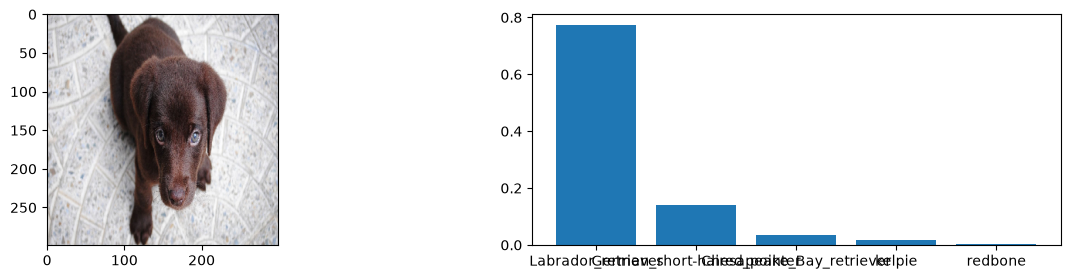

In [15]:
resultado_Inception = tensorflow.keras.applications.inception_v3.decode_predictions(features_Inception, top=5)[0]

resultado_top5_Inception = np.array([resultado_Inception [0][2], resultado_Inception [1][2],resultado_Inception [2][2], resultado_Inception [3][2], resultado_Inception [4][2]])
labels_top5_Inception = np.array([resultado_Inception [0][1], resultado_Inception [1][1],resultado_Inception [2][1], resultado_Inception [3][1], resultado_Inception [4][1]])

print('Resultado:\nLabels: ', labels_top5_Inception, '\nProbabilidades:', resultado_top5_Inception)

plt.figure(figsize=(15,3))
plt.subplot(1,2,1)
plt.imshow(img_Inception)
plt.subplot(1,2,2)
plt.bar(range(5), resultado_top5_Inception, tick_label= labels_top5_Inception)
plt.show()

Resultado:
Labels:  ['flat-coated_retriever' 'Labrador_retriever' 'kelpie' 'groenendael'
 'schipperke'] 
Probabilidades: [0.42803457 0.2943643  0.14970131 0.04048963 0.02510555]


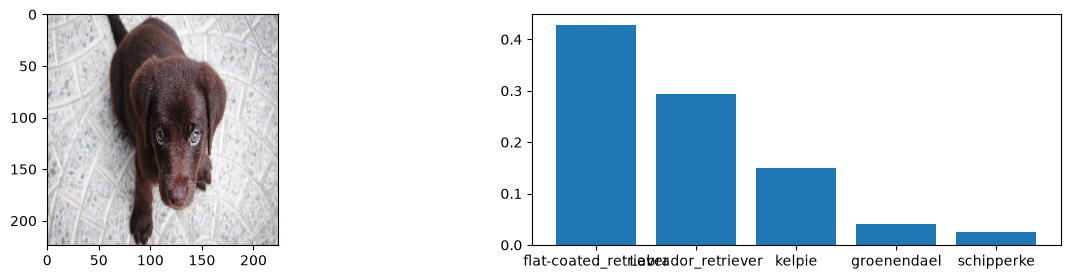

In [16]:
resultado_VGG = tensorflow.keras.applications.vgg19.decode_predictions(features_VGG, top=10)[0]
resultado_top5_vgg = np.array([resultado_VGG[0][2], resultado_VGG[1][2],resultado_VGG[2][2], resultado_VGG[3][2], resultado_VGG[4][2]])
labels_top5_vgg = np.array([resultado_VGG[0][1], resultado_VGG[1][1],resultado_VGG[2][1], resultado_VGG[3][1], resultado_VGG[4][1]])

print('Resultado:\nLabels: ', labels_top5_vgg, '\nProbabilidades:', resultado_top5_vgg)

plt.figure(figsize=(15,3))
plt.subplot(1,2,1)
plt.imshow(img_VGG)
plt.subplot(1,2,2)
plt.bar(range(5), resultado_top5_vgg, tick_label= labels_top5_vgg)
plt.show()